# Refractory violations and L2: numerical model (mine) at 4 interior conductivities vs analytical model (Denis' pipeline), 71 Kaden 4-fish recordings

Same violation rule as `EOD_refractory_violations_denis_mask_midline_71_kaden_4fish.ipynb`:
- **violation** = two consecutive detected EODs (in time) **< 6.5 ms** apart, both given to the same fish;
- pairs are formed over all detected EODs (an unassigned EOD still sits between its neighbours) and count only when both EODs are
  assigned; reported as **% of the valid consecutive pairs** of the recording.

**Models** (all with the mask midlines of Kaden's visible masks, no refractory step):
- **my model, interior 1, 4, 16, 100 x water**: cluster run `cluster_kaden_4fish_assign.py` (MODEL=mine), files
  `results/eod_assign_4fish_kaden/cluster_assign/mine_N150_tank_barriers_int<s>/Voltage_prediction_4fish_2024-02-20T<video>.npz`;
- **Denis' pipeline**: the run of 2026-11-06 (`results/eod_assign_4fish_kaden/<video>/denis_assignments.csv`, built from his
  `denis/Assigned_Data_4fish_2024-02-20T<video>.pkl`), and his voltage-rule picks in `l2_distributions/denis_71/denis_71_l2_per_eod.csv.gz`.

**Rules** (which fish gets the EOD):
- **L2 shape**: recorded and predicted 10-pair patterns each scaled to max |v| = 1, smallest L2 (mine: `pick_shape`; Denis: `fish | Denis, L2 (max |v| = 1)`);
- **cosine**: highest cosine similarity between recorded and predicted patterns (mine: computed here from `recorded` and
  `model_sign x model_raw`; Denis: his own pick, `fish | Denis, similarity`);
- **voltage L2**: median fish x signed-electrode factors, smallest L2 in volts (mine: `pick_voltage`, factors fitted on the interior-4
  model and used for every conductivity; Denis: his factors from the 100 best clean EODs per fish per recording).

Recorded pattern: mine = main phase (demeaned traces at the sample of the largest |V|); Denis = his signed peak-to-peak.
Assigned EODs: Denis needs all four midlines; my model predicts every fish that has one, so it assigns ~5% more EODs.
Two EOD sets are therefore compared:
- **all assigned**: every model with all the EODs it assigns;
- **Denis' EOD set**: only the EODs Denis assigns (every fish has a midline); my model's other EODs are counted as unassigned, so
  every model is scored on exactly the same EODs and the same consecutive pairs.

**Names in the plots:** *numerical* = my 2D resistive model (interior 1, 4, 16, 100 x water); *analytical* = Denis' pipeline (his 1/r
field with mirror images). Each has its **own** voltage-rule factors (fish x signed electrode medians fitted on its own predictions):
numerical on the 1000 best clean isolated EODs per fish (interior-4 model), analytical on the 100 best per fish per recording.

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE = 'results/eod_assign_4fish_kaden'
OUT = f'{BASE}/refractory_violations/conductivities_vs_denis'; os.makedirs(OUT, exist_ok=True)
FISH, LIM_MS = 'ABCD', 6.5
SIGMAS = [1, 4, 16, 100]
MODELS = [f'numerical, interior {s}' for s in SIGMAS] + ['analytical']
RULES = ['L2 shape', 'cosine', 'voltage L2']
COL = {'numerical, interior 1': '#9ecae1', 'numerical, interior 4': '#4292c6', 'numerical, interior 16': '#2166ac',
       'numerical, interior 100': '#08306b', 'analytical': '#e6550d'}
TRACE_MODELS = ['numerical, interior 4', 'analytical']     # the lines of the plots over time
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True})
VIDEOS = sorted(v[-12:-4] for v in os.listdir(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4') if v.startswith('Voltage_prediction_4fish_2024-02-20T') and v.endswith('.npz'))
hours = lambda t: int(t[:2]) + int(t[3:5]) / 60 + int(t[6:8]) / 3600
print(len(VIDEOS), 'recordings,', VIDEOS[0], '...', VIDEOS[-1])

71 recordings, 00_12_52 ... 23_56_27


In [2]:
def labels(picks):
    '''fish letters ('' = unassigned) -> index 0-3, -1 unassigned'''
    return pd.Series(picks).map({f: i for i, f in enumerate(FISH)}).fillna(-1).astype(int).to_numpy()

def cosine_pick(rec, pred):
    '''highest cosine similarity between rec (n, 10) and pred (n, 4, 10); -1 where no fish has a prediction'''
    cos = np.einsum('np,nfp->nf', rec, pred) / (np.linalg.norm(rec, axis=1)[:, None] * np.linalg.norm(pred, axis=2))
    ok = np.isfinite(cos).any(1)
    return np.where(ok, np.nanargmax(np.where(np.isfinite(cos), cos, -np.inf), 1), -1)

def violations(dt_ms, k):
    valid = (k[1:] >= 0) & (k[:-1] >= 0)
    v = valid & (k[1:] == k[:-1]) & (dt_ms < LIM_MS)
    return dict(valid_pairs=int(valid.sum()), violations=int(v.sum()), assigned=int((k >= 0).sum()),
                pct=100 * v.sum() / max(valid.sum(), 1))

DV = pd.read_csv(f'{BASE}/l2_distributions/denis_71/denis_71_l2_per_eod.csv.gz', usecols=['video', 'row', 'pick_voltage'],
                 keep_default_na=False)
DV = {t: g.sort_values('row').pick_voltage.to_numpy() for t, g in DV.groupby('video')}
rows = []
for t in VIDEOS:
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Frame', 'Time', 'all fish have a midline', 'fish | Denis, similarity',
                    'fish | Denis, L2 (max |v| = 1)'], keep_default_na=False)
    time = d.Time.to_numpy(); assert np.all(np.diff(time) >= 0), t
    dt = np.diff(time) * 1000
    K = {('analytical', 'L2 shape'): labels(d['fish | Denis, L2 (max |v| = 1)']), ('analytical', 'cosine'): labels(d['fish | Denis, similarity']),
         ('analytical', 'voltage L2'): labels(DV[t])}
    assert len(DV[t]) == len(d), t
    for s in SIGMAS:
        z = np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int{s}/Voltage_prediction_4fish_2024-02-20T{t}.npz')
        assert (z['eod_rows'] == np.arange(len(d))).all() and (z['frames'] == d.Frame.to_numpy()).all(), (t, s)
        m = f'numerical, interior {s}'
        K[(m, 'L2 shape')] = labels(z['pick_shape']); K[(m, 'voltage L2')] = labels(z['pick_voltage'])
        K[(m, 'cosine')] = cosine_pick(z['recorded'], int(z['model_sign']) * z['model_raw'])
    dset = d['all fish have a midline'].astype(str).str.lower().eq('true').to_numpy()     # the EODs the analytical model assigns
    assert (K[('analytical', 'cosine')][~dset] == -1).all(), t
    for (m, r), k in K.items():
        for name, kk in (('all assigned', k), ("EODs with all 4 midlines", np.where(dset, k, -1))):
            rows.append(dict(recording=t, hour=hours(t), model=m, rule=r, set=name, EODs=len(k), **violations(dt, kk)))
V = pd.DataFrame(rows); V.to_csv(f'{OUT}/refractory_violations_per_recording_{LIM_MS:g}ms.csv', index=False)
print(f'{V.recording.nunique()} recordings, {V[(V.model == "analytical") & (V.rule == "cosine") & (V.set == "all assigned")].EODs.sum():,} detected EODs; '
      f'< {LIM_MS:g} ms, % of valid consecutive pairs')
V.pivot_table(index='model', columns=['set', 'rule'], values='assigned', aggfunc='sum').reindex(MODELS).rename_axis(None).style.format('{:,.0f}')\
 .set_caption('assigned EODs (all 71 recordings)')

71 recordings, 3,667,494 detected EODs; < 6.5 ms, % of valid consecutive pairs


## Violations through the day

One point per recording, at its start time (the 71 recordings of 2024-02-20 in chronological order); one panel per rule; lines:
the numerical model with interior 4 and the analytical model (all conductivities are in the bar plots).

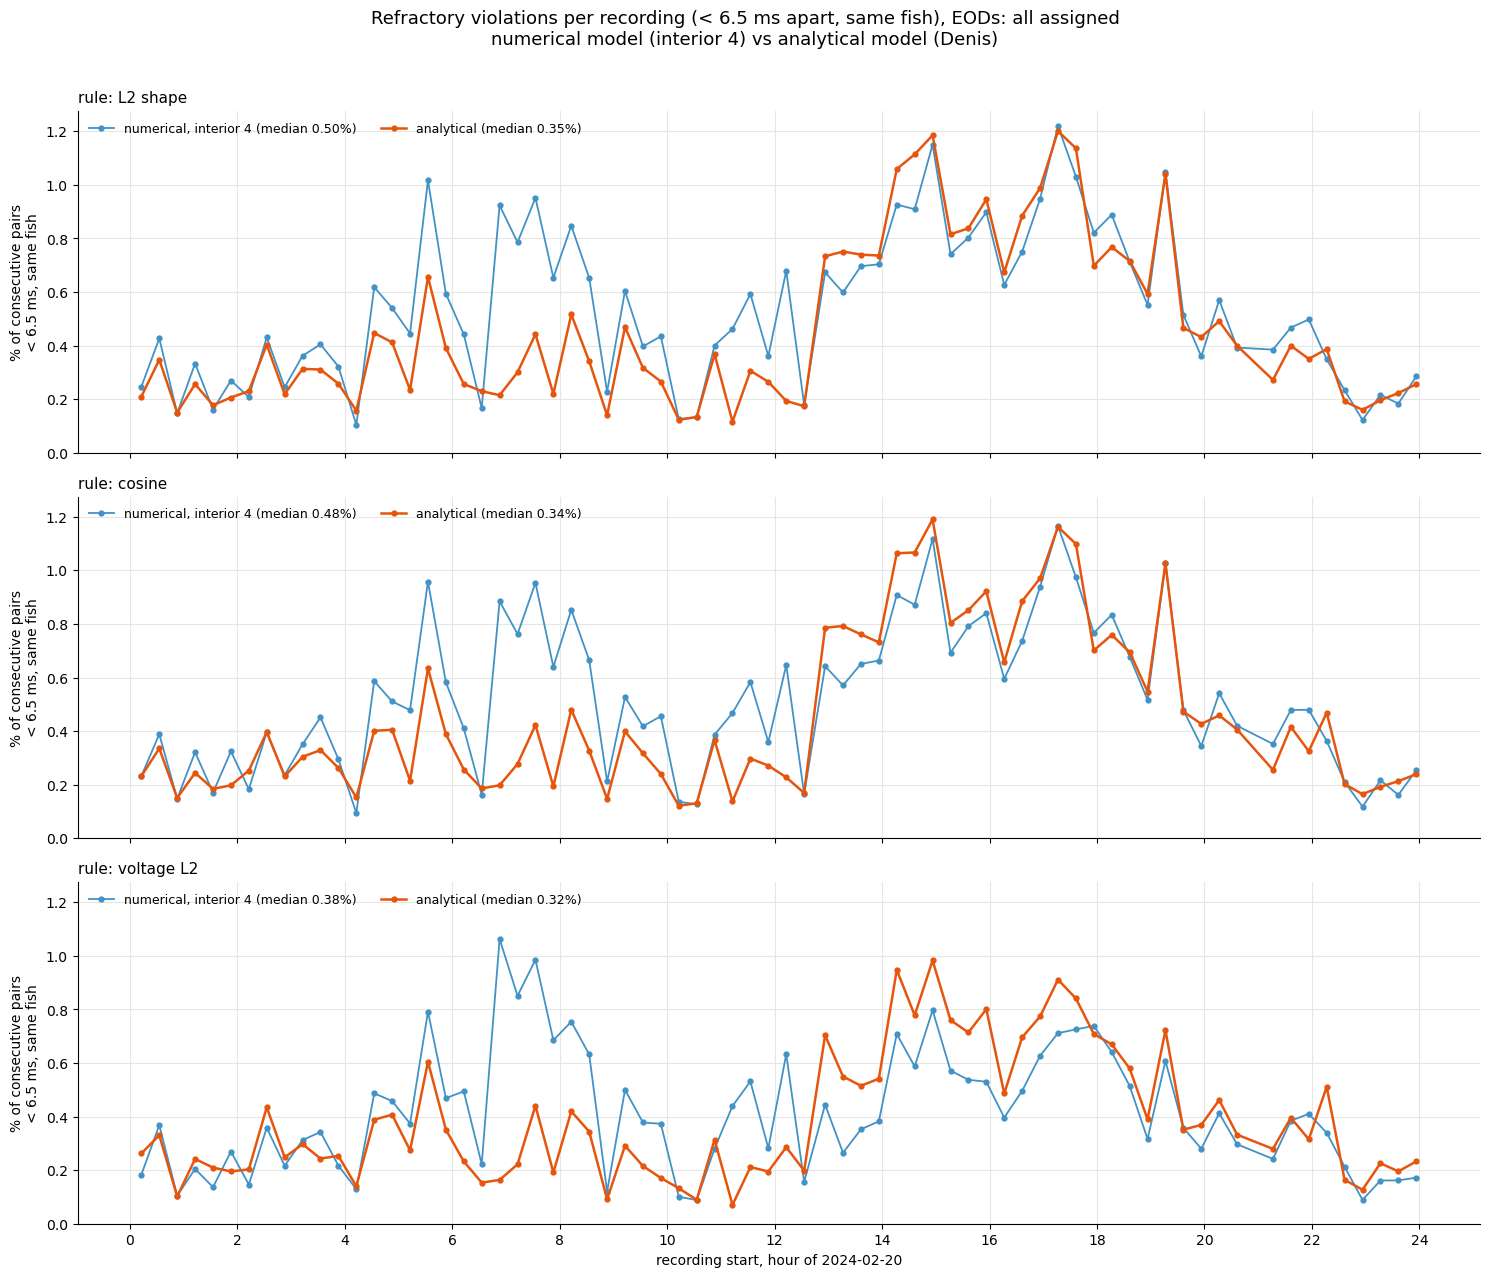

In [3]:
def plot_time(S, fname):
    fig, axs = plt.subplots(len(RULES), 1, figsize=(15, 4.2 * len(RULES)), sharex=True, sharey=True)
    for ax, r in zip(axs, RULES):
        for m in TRACE_MODELS:
            g = V[(V.set == S) & (V.model == m) & (V.rule == r)].sort_values('hour')
            ax.plot(g.hour, g.pct, '-o', ms=3.5, lw=1.3 if m != 'analytical' else 1.8, color=COL[m], label=f'{m} (median {g.pct.median():.2f}%)')
        ax.set_title(f'rule: {r}', fontsize=11, loc='left'); ax.set_ylabel(f'% of consecutive pairs\n< {LIM_MS:g} ms, same fish')
        ax.legend(frameon=False, fontsize=9, ncol=2, loc='upper left'); ax.set_ylim(0, None)
    axs[-1].set_xlabel('recording start, hour of 2024-02-20'); axs[-1].set_xticks(range(0, 25, 2))
    fig.suptitle(f'Refractory violations per recording (< {LIM_MS:g} ms apart, same fish), EODs: {S}\n'
                 'numerical model (interior 4) vs analytical model (Denis)', y=1.01, fontsize=13)
    plt.tight_layout(); fig.savefig(f'{OUT}/{fname}', dpi=110, bbox_inches='tight'); plt.show()

plot_time('all assigned', f'violations_vs_time_{LIM_MS:g}ms.png')

## Median over the 71 recordings

Bars: median % violations over the recordings; whiskers: 25th-75th percentile; dots: the recordings.

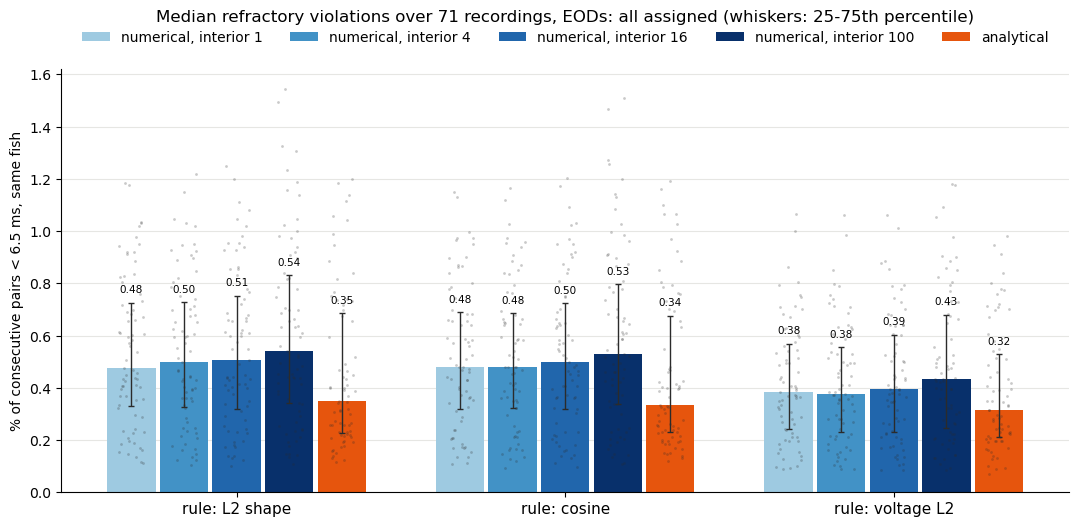

rule,L2 shape,cosine,voltage L2
"numerical, interior 1",0.477,0.481,0.384
"numerical, interior 4",0.498,0.479,0.378
"numerical, interior 16",0.505,0.500,0.394
"numerical, interior 100",0.540,0.529,0.432
analytical,0.351,0.335,0.315


In [4]:
def plot_bars(S, fname):
    W = V[V.set == S]
    M = W.groupby(['rule', 'model']).pct.agg(median='median', q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75), mean='mean').reset_index()
    fig, ax = plt.subplots(figsize=(13, 5.5)); w = 0.16; rng = np.random.default_rng(0)
    for i, r in enumerate(RULES):
        for j, m in enumerate(MODELS):
            x = i + (j - 2) * w; s = M[(M.rule == r) & (M.model == m)].iloc[0]; y = W[(W.rule == r) & (W.model == m)].pct.to_numpy()
            ax.bar(x, s['median'], w * 0.92, color=COL[m], label=m if i == 0 else None)
            ax.errorbar(x, s['median'], yerr=[[s['median'] - s.q25], [s.q75 - s['median']]], color='#2b2b2b', lw=1, capsize=2.5)
            ax.scatter(x + rng.uniform(-w / 4, w / 4, len(y)), y, s=4, color='#2b2b2b', alpha=0.25, zorder=3, linewidths=0)
            ax.text(x, s.q75 + 0.03, f'{s["median"]:.2f}', ha='center', va='bottom', fontsize=7.5)
    ax.set_xticks(range(len(RULES))); ax.set_xticklabels([f'rule: {r}' for r in RULES], fontsize=11)
    ax.set_ylabel(f'% of consecutive pairs < {LIM_MS:g} ms, same fish'); ax.grid(axis='x', visible=False)
    ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, 1.12))
    ax.set_title(f'Median refractory violations over {W.recording.nunique()} recordings, EODs: {S} (whiskers: 25-75th percentile)', pad=34)
    fig.savefig(f'{OUT}/{fname}', dpi=110, bbox_inches='tight'); plt.show()
    return M

M = plot_bars('all assigned', f'violations_median_bar_{LIM_MS:g}ms.png')
M.pivot(index='model', columns='rule', values='median').reindex(MODELS)[RULES].rename_axis(None).round(3)

## Same EOD set for every model: only the EODs with all 4 midlines (the EODs the analytical model assigns)

My model's EODs where some fish has no midline (which Denis leaves unassigned) are counted as unassigned here, so all five models
are scored on the same EODs and the same consecutive pairs.

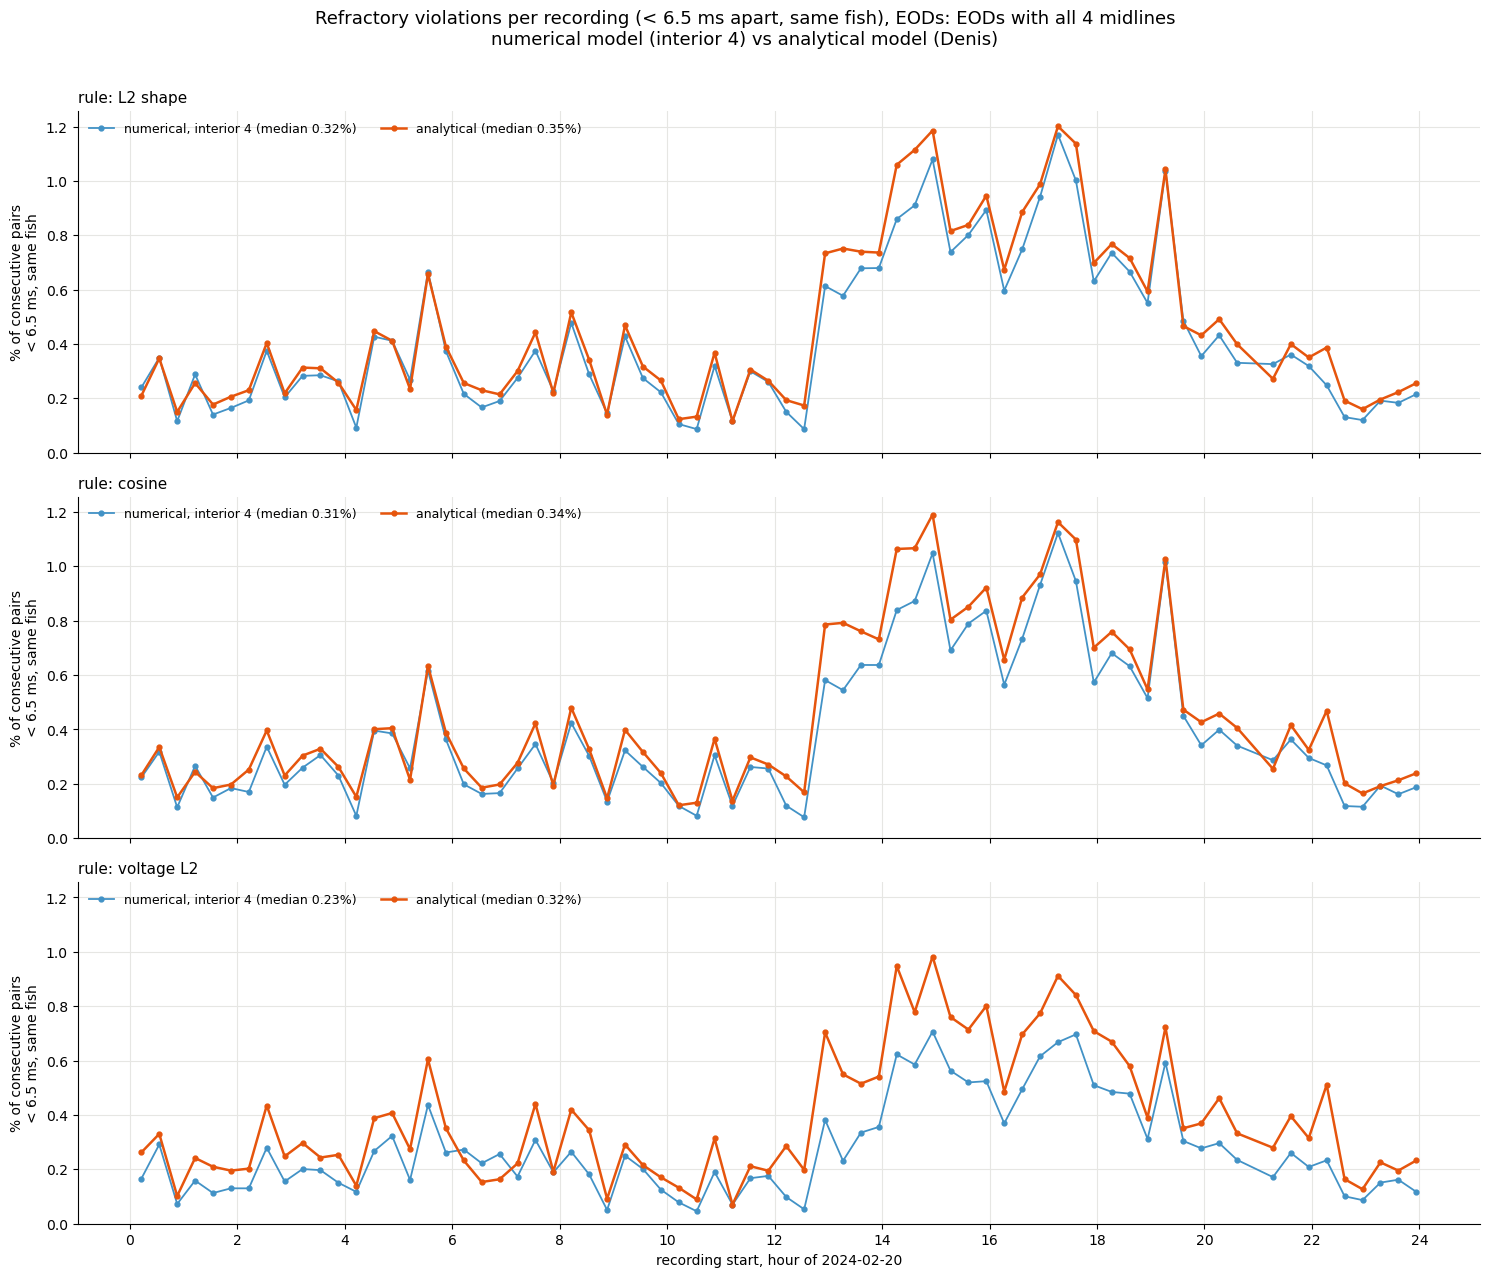

In [5]:
plot_time("EODs with all 4 midlines", f'violations_vs_time_{LIM_MS:g}ms_denis_eod_set.png')

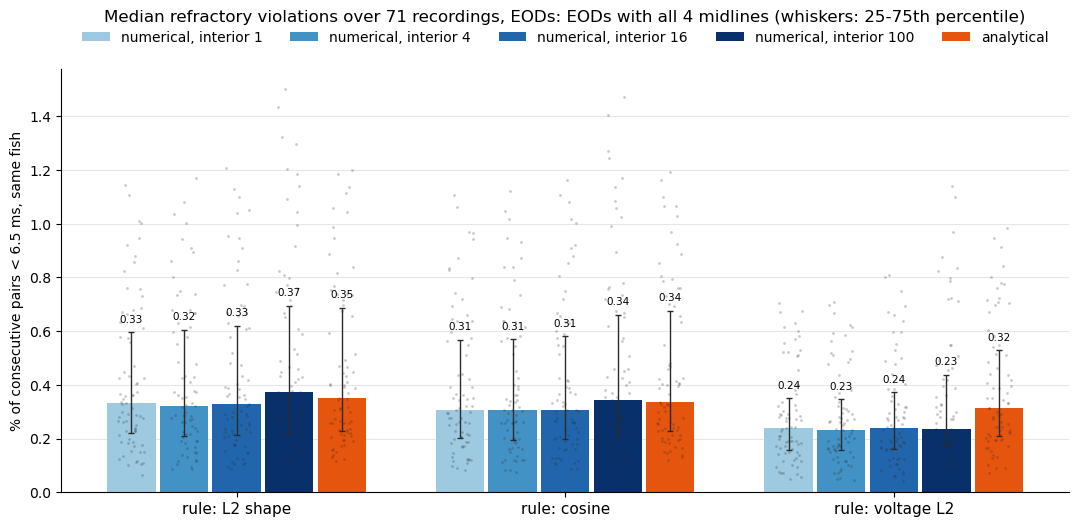

set                     EODs with all 4 midlines                    \
rule                                    L2 shape cosine voltage L2   
numerical, interior 1                      0.331  0.305      0.238   
numerical, interior 4                      0.320  0.305      0.233   
numerical, interior 16                     0.329  0.307      0.238   
numerical, interior 100                    0.373  0.342      0.235   
analytical                                 0.351  0.335      0.315   

set                     all assigned                    
rule                        L2 shape cosine voltage L2  
numerical, interior 1          0.477  0.481      0.384  
numerical, interior 4          0.498  0.479      0.378  
numerical, interior 16         0.505  0.500      0.394  
numerical, interior 100        0.540  0.529      0.432  
analytical                     0.351  0.335      0.315

In [6]:
M2 = plot_bars("EODs with all 4 midlines", f'violations_median_bar_{LIM_MS:g}ms_denis_eod_set.png')
M_all = V.groupby(['set', 'rule', 'model']).pct.median().unstack(['set', 'rule']).reindex(MODELS)
M_all.to_csv(f'{OUT}/violations_median_{LIM_MS:g}ms.csv')
M_all.rename_axis(None).round(3)

## L2 between the recording and the assigned fish's prediction

On the EODs with all 4 midlines (every model assigns them). For each EOD, the L2 of the fish the rule picked:
- **normalized** (shape rule): recorded and predicted patterns each scaled to max |v| = 1 (0 = same shape);
- **not normalized** (voltage rule): ||recorded - predicted volts||, divided by max |recorded| only so the two models' recorded
  quantities (numerical: main phase; analytical: signed peak-to-peak) are on one scale (0 = perfect, 1 = an error as large as the peak).

Lines over time: median over the recording's EODs (numerical interior 4 and analytical); bars: median over the 71 recordings.

In [7]:
def pick_l2(L2, k):
    '''L2 (n, 4) of the picked fish k (n,), NaN where unassigned'''
    return np.where(k >= 0, L2[np.arange(len(k)), np.clip(k, 0, None)], np.nan)

L2_RULES = {'normalized': 'shape L2 (max |v| = 1)', 'not normalized': 'voltage L2 / max |recorded|'}
DR = pd.read_csv(f'{BASE}/l2_distributions/denis_71/denis_71_l2_per_eod.csv.gz', usecols=['video', 'row', 'l2_rel'])
DR = {t: g.sort_values('row').l2_rel.to_numpy() for t, g in DR.groupby('video')}
rows = []
for t in VIDEOS:
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', keep_default_na=False,
                    usecols=['all fish have a midline', 'fish | Denis, L2 (max |v| = 1)'] + [f'L2 {f} (max |v| = 1)' for f in FISH])
    dset = d['all fish have a midline'].astype(str).str.lower().eq('true').to_numpy()
    LS = d[[f'L2 {f} (max |v| = 1)' for f in FISH]].replace('', np.nan).astype(float).to_numpy()
    X = {('analytical', 'normalized'): pick_l2(LS, labels(d['fish | Denis, L2 (max |v| = 1)'])), ('analytical', 'not normalized'): DR[t]}
    for s in SIGMAS:
        z = np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int{s}/Voltage_prediction_4fish_2024-02-20T{t}.npz'); m = f'numerical, interior {s}'
        X[(m, 'normalized')] = pick_l2(z['l2_shape'], labels(z['pick_shape']))
        X[(m, 'not normalized')] = pick_l2(z['l2_rel'], labels(z['pick_voltage']))
    for (m, r), x in X.items():
        x = x[dset & np.isfinite(x)]
        rows.append(dict(recording=t, hour=hours(t), model=m, rule=r, n=len(x), median=np.median(x), q25=np.quantile(x, 0.25),
                         q75=np.quantile(x, 0.75), mean=x.mean()))
L = pd.DataFrame(rows); L.to_csv(f'{OUT}/assigned_l2_per_recording_denis_eod_set.csv', index=False)
L.pivot_table(index='model', columns='rule', values='n', aggfunc='sum').reindex(MODELS)[list(L2_RULES)].rename_axis(None).style.format('{:,.0f}')\
 .set_caption('EODs with an L2 (all 4 midlines, 71 recordings)')

/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_9031/2579187147.py:10: DtypeWarning: Columns (7,9,11,13) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', keep_default_na=False,


/var/folders/w4/p225s7cd19n0j6tss7pdl21w0000gn/T/ipykernel_9031/2579187147.py:10: DtypeWarning: Columns (7,9,11,13) have mixed types. Specify dtype option on import or set low_memory=False.
  d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', keep_default_na=False,


rule,normalized,not normalized
"numerical, interior 1","3,498,431","3,498,431"
"numerical, interior 4","3,498,431","3,498,431"
"numerical, interior 16","3,498,431","3,498,431"
"numerical, interior 100","3,498,431","3,498,431"
analytical,"3,498,433","3,498,433"


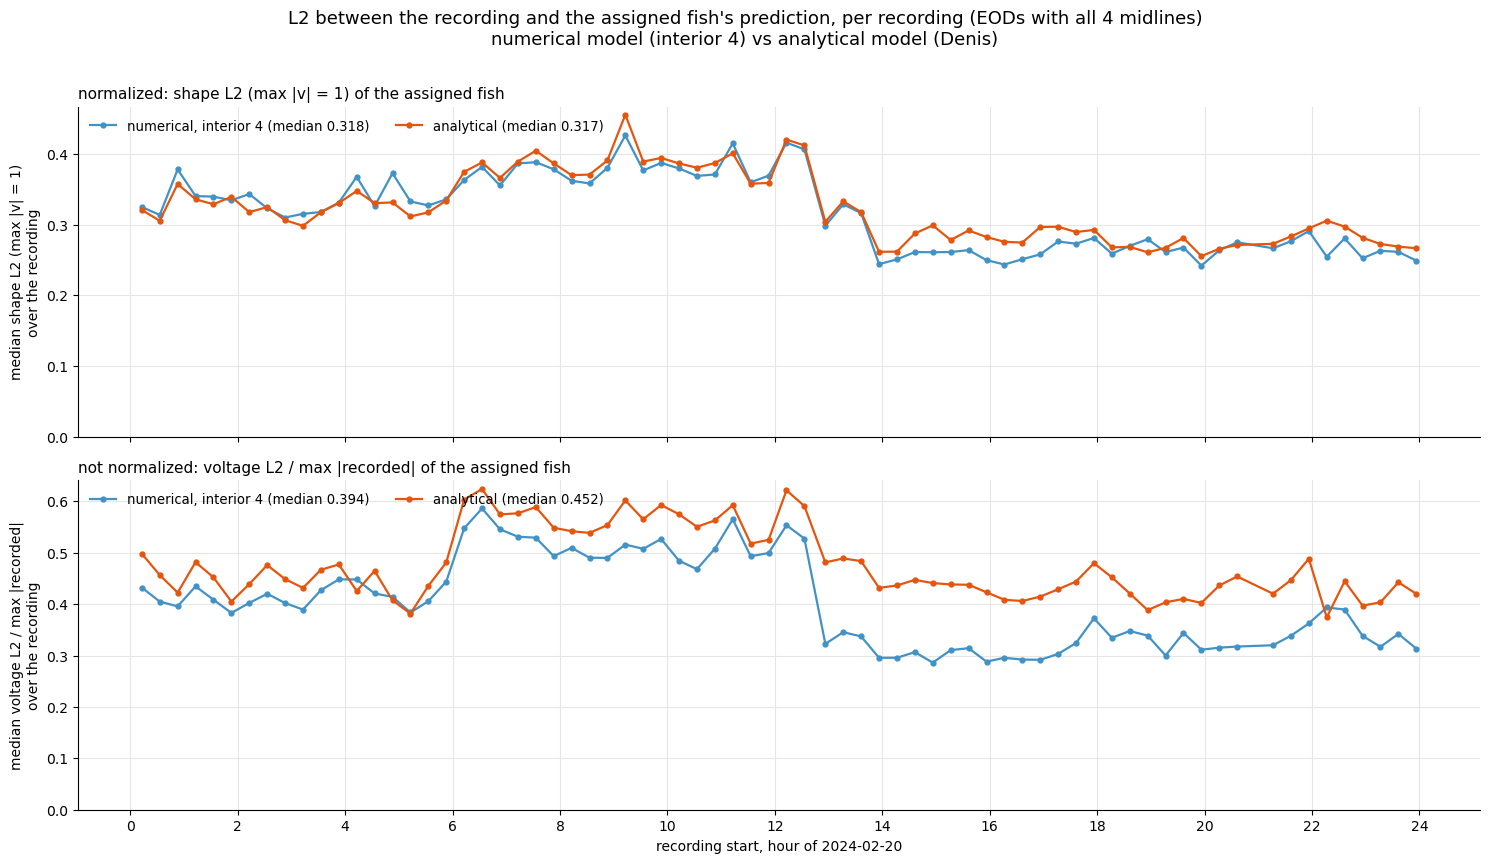

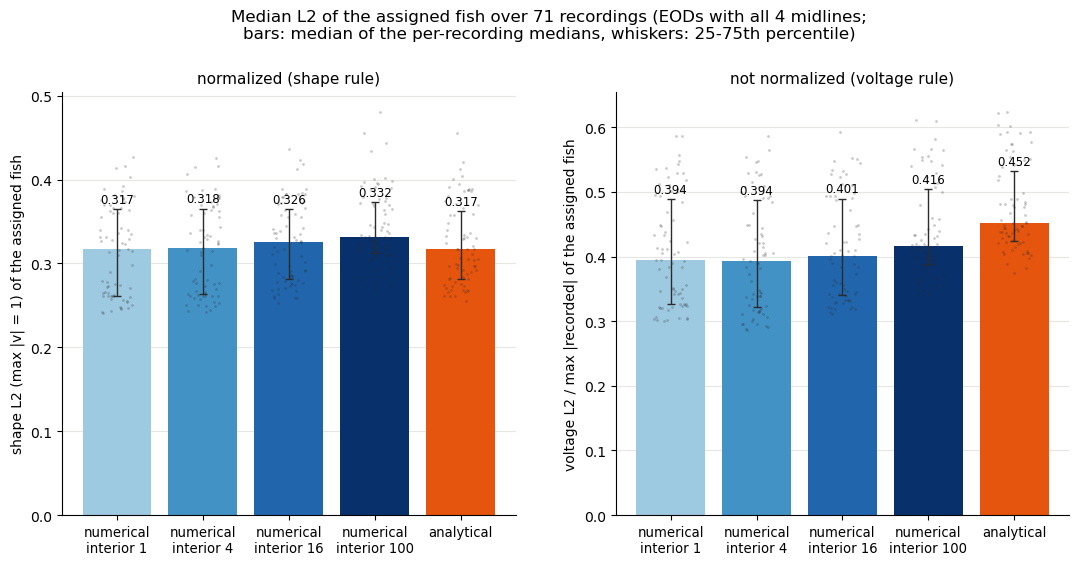

rule,normalized,not normalized
"numerical, interior 1",0.3174,0.3940
"numerical, interior 4",0.3178,0.3936
"numerical, interior 16",0.3255,0.4012
"numerical, interior 100",0.3320,0.4158
analytical,0.3174,0.4521


In [8]:
fig, axs = plt.subplots(2, 1, figsize=(15, 8.5), sharex=True)
for ax, (r, yl) in zip(axs, L2_RULES.items()):
    for m in TRACE_MODELS:
        g = L[(L.model == m) & (L.rule == r)].sort_values('hour')
        ax.plot(g.hour, g['median'], '-o', ms=3.5, lw=1.6, color=COL[m], label=f'{m} (median {g["median"].median():.3f})')
    ax.set_title(f'{r}: {yl} of the assigned fish', fontsize=11, loc='left'); ax.set_ylabel(f'median {yl}\nover the recording')
    ax.legend(frameon=False, fontsize=9.5, ncol=2, loc='upper left'); ax.set_ylim(0, None)
axs[-1].set_xlabel('recording start, hour of 2024-02-20'); axs[-1].set_xticks(range(0, 25, 2))
fig.suptitle("L2 between the recording and the assigned fish's prediction, per recording (EODs with all 4 midlines)\n"
             'numerical model (interior 4) vs analytical model (Denis)', y=1.01, fontsize=13)
plt.tight_layout(); fig.savefig(f'{OUT}/assigned_l2_vs_time_denis_eod_set.png', dpi=110, bbox_inches='tight'); plt.show()

ML = L.groupby(['rule', 'model'])['median'].agg(median='median', q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw=dict(wspace=0.22)); rng = np.random.default_rng(0)
for ax, (r, yl) in zip(axs, L2_RULES.items()):
    for j, m in enumerate(MODELS):
        s = ML[(ML.rule == r) & (ML.model == m)].iloc[0]; y = L[(L.rule == r) & (L.model == m)]['median'].to_numpy()
        ax.bar(j, s['median'], 0.8, color=COL[m])
        ax.errorbar(j, s['median'], yerr=[[s['median'] - s.q25], [s.q75 - s['median']]], color='#2b2b2b', lw=1, capsize=3)
        ax.scatter(j + rng.uniform(-0.2, 0.2, len(y)), y, s=4, color='#2b2b2b', alpha=0.25, zorder=3, linewidths=0)
        ax.text(j, s.q75 * 1.01, f'{s["median"]:.3f}', ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels([m.replace(', ', '\n') for m in MODELS], fontsize=9.5); ax.grid(axis='x', visible=False)
    ax.set_title(f'{r} ({"shape rule" if r == "normalized" else "voltage rule"})', fontsize=11); ax.set_ylabel(f'{yl} of the assigned fish')
fig.suptitle(f"Median L2 of the assigned fish over {L.recording.nunique()} recordings (EODs with all 4 midlines;\nbars: median of the "
             'per-recording medians, whiskers: 25-75th percentile)', y=1.03)
fig.savefig(f'{OUT}/assigned_l2_median_bar_denis_eod_set.png', dpi=110, bbox_inches='tight'); plt.show()
ML.to_csv(f'{OUT}/assigned_l2_median_denis_eod_set.csv', index=False)
ML.pivot(index='model', columns='rule', values='median').reindex(MODELS)[list(L2_RULES)].rename_axis(None).round(4)

## Distribution of the voltage-rule L2 per 6 hours of the day

Numerical model (interior 4) and analytical model, voltage rule, EODs with all 4 midlines: the L2 of the assigned fish relative to
the recording's peak (||recorded - predicted volts|| / max |recorded|), one value per EOD, pooled over the recordings that start in
each 6-hour block (00-06, 06-12, 12-18, 18-24 h). Values above the last bin are counted in it.

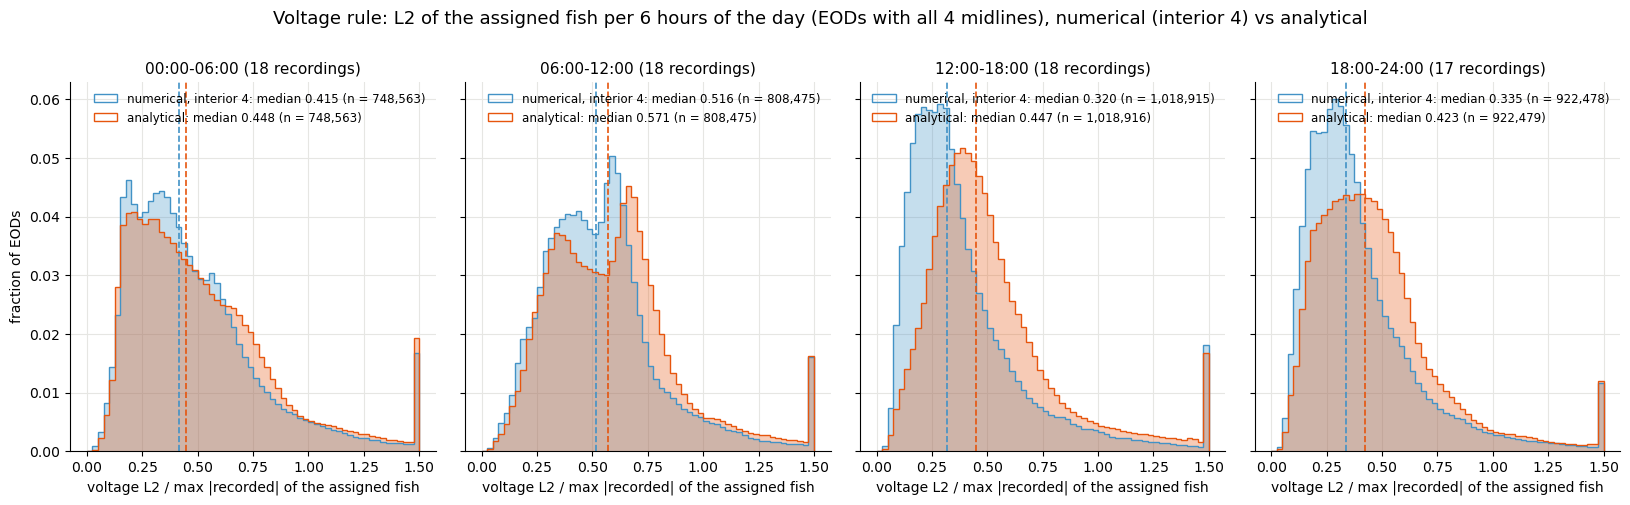

,block,model,recordings,EODs,median,q25,q75,share_above_1
0,00-06 h,"numerical, interior 4",18,748563,0.415,0.268,0.617,6.652
1,00-06 h,analytical,18,748563,0.448,0.277,0.676,7.877
2,06-12 h,"numerical, interior 4",18,808475,0.516,0.357,0.658,6.534
3,06-12 h,analytical,18,808475,0.571,0.375,0.730,7.965
4,12-18 h,"numerical, interior 4",18,1018915,0.320,0.213,0.484,5.082
5,12-18 h,analytical,18,1018916,0.447,0.323,0.615,7.068
6,18-24 h,"numerical, interior 4",17,922478,0.335,0.227,0.492,4.145
7,18-24 h,analytical,17,922479,0.423,0.279,0.582,4.902


In [9]:
BLOCKS = [(0, 6), (6, 12), (12, 18), (18, 24)]
PER = {m: {b: [] for b in BLOCKS} for m in TRACE_MODELS}
for t in VIDEOS:
    b = next(b for b in BLOCKS if b[0] <= hours(t) < b[1])
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['all fish have a midline'], keep_default_na=False)
    dset = d['all fish have a midline'].astype(str).str.lower().eq('true').to_numpy()
    z = np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4/Voltage_prediction_4fish_2024-02-20T{t}.npz')
    for m, x in (('numerical, interior 4', pick_l2(z['l2_rel'], labels(z['pick_voltage']))), ('analytical', DR[t])):
        PER[m][b].append(x[dset & np.isfinite(x)])
PER = {m: {b: np.concatenate(v) for b, v in pb.items()} for m, pb in PER.items()}

bins = np.linspace(0, 1.5, 61)
fig, axs = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True, gridspec_kw=dict(wspace=0.08)); rows = []
for ax, b in zip(axs, BLOCKS):
    nrec = sum(b[0] <= hours(t) < b[1] for t in VIDEOS)
    for m in TRACE_MODELS:
        x = PER[m][b]; w = np.ones(len(x)) / len(x); med = np.median(x)
        ax.hist(np.clip(x, bins[0], bins[-1]), bins=bins, weights=w, histtype='stepfilled', alpha=0.3, color=COL[m])
        ax.hist(np.clip(x, bins[0], bins[-1]), bins=bins, weights=w, histtype='step', lw=1.6, color=COL[m],
                label=f'{m}: median {med:.3f} (n = {len(x):,})')
        ax.axvline(med, color=COL[m], ls='--', lw=1.2)
        rows.append(dict(block=f'{b[0]:02d}-{b[1]:02d} h', model=m, recordings=nrec, EODs=len(x), median=med,
                         q25=np.quantile(x, 0.25), q75=np.quantile(x, 0.75), share_above_1=(x > 1).mean() * 100))
    ax.set_title(f'{b[0]:02d}:00-{b[1]:02d}:00 ({nrec} recordings)', fontsize=11)
    ax.set_xlabel('voltage L2 / max |recorded| of the assigned fish'); ax.legend(frameon=False, fontsize=8.5, loc='upper right')
axs[0].set_ylabel('fraction of EODs')
fig.suptitle('Voltage rule: L2 of the assigned fish per 6 hours of the day (EODs with all 4 midlines), numerical (interior 4) vs analytical',
             y=1.03, fontsize=13)
fig.savefig(f'{OUT}/voltage_l2_distribution_per_6h_denis_eod_set.png', dpi=110, bbox_inches='tight'); plt.show()
B6 = pd.DataFrame(rows); B6.to_csv(f'{OUT}/voltage_l2_per_6h_denis_eod_set.csv', index=False); B6.round(3)

## Fair factor test: the analytical model's factors refitted on the numerical model's clean set

The two models' voltage-rule factors came from different clean sets (numerical: the 1000 best clean isolated EODs per fish, all
recordings pooled; analytical: the 100 best per fish per recording). Here the analytical factors are refitted on **the same 4000
EODs** as the numerical ones (`clean_emitter_set_71/best1000_per_fish_71.csv`), with the same procedure as his first fit:
- per EOD, the emitter's ratios |recorded PTP| / |predicted PTP| on the 2 loudest recorded pairs (same sign, predicted |v| >= 5% of
  the emitter's max);
- fish factor a_f = median of the fish's ratios; signed-electrode factor e_k = median of ratio / a_f over the ratios on electrode k
  (the pole of the pair nearer to the emitter's midline; Denis' electrode layout).

Then his voltage rule is rerun on every EOD of the 71 recordings and scored like the others (EODs with all 4 midlines).

In [10]:
EL = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv').sort_values('pair')
PLUS = np.array([(r.x1, r.y1) if str(r.pol1).strip() == '+' else (r.x2, r.y2) for _, r in EL.iterrows()], float)
MINUS = np.array([(r.x2, r.y2) if str(r.pol1).strip() == '+' else (r.x1, r.y1) for _, r in EL.iterrows()], float)
ORDER = [f'{p}{s}' for p in range(1, 11) for s in ('+', '−')]

def nearer_pole(mids, chunk=1500):
    '''(n, 4, 10): 0 = + pole of the pair nearer to the fish's midline, 1 = - pole (0 where no midline); Denis' electrodes'''
    out = np.zeros(mids.shape[:2] + (10,), np.int8)
    for s in range(0, len(mids), chunk):
        xy = mids[s:s + chunk, :, :, ::-1] * 911
        dp = np.linalg.norm(xy[:, :, :, None] - PLUS[None, None, None], axis=-1).min(2)
        dm = np.linalg.norm(xy[:, :, :, None] - MINUS[None, None, None], axis=-1).min(2)
        out[s:s + chunk] = (dm < dp)
    return out

S1000 = pd.read_csv(f'{BASE}/clean_emitter_set_71/best1000_per_fish_71.csv')
rat = []
for t, g in S1000.groupby('video'):
    z = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True); R_, M_ = z['recorded_ptp'], z['predicted_ptp']
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}; mids = mz['mids']
    for r in g.itertuples():
        j = FISH.index(r.fish); rec, pr = R_[r.row], M_[r.row, j]
        if not np.isfinite(pr).all(): continue
        pole = nearer_pole(mids[[gi[int(r.Frame)]]])[0, j]
        for q in np.argsort(-np.abs(rec))[:2]:
            if np.sign(rec[q]) == np.sign(pr[q]) and abs(pr[q]) >= 0.05 * np.abs(pr).max():
                rat.append(dict(video=t, row=r.row, fish=r.fish, pair=q + 1, electrode=f'{q + 1}{"+−"[pole[q]]}', gain=abs(rec[q]) / abs(pr[q])))
RT = pd.DataFrame(rat); RT.to_csv(f'{BASE}/l2_distributions/denis_71/factor_ratios_best1000.csv', index=False)
A_F = RT.groupby('fish').gain.median(); RT['g_over_a'] = RT.gain / RT.fish.map(A_F)
E_K = RT.groupby('electrode').g_over_a.median().reindex(ORDER).fillna(1.0)
FAC1000 = pd.DataFrame({'factor': [f'fish {f}' for f in FISH] + [f'electrode {e}' for e in ORDER],
                        'value': list(A_F.reindex(list(FISH))) + list(E_K),
                        'n_ratios': list(RT.fish.value_counts().reindex(list(FISH))) + list(RT.electrode.value_counts().reindex(ORDER).fillna(0).astype(int))})
FAC1000.to_csv(f'{BASE}/l2_distributions/denis_71/denis_voltage_rule_factors_median_best1000.csv', index=False)
FAC100 = pd.read_csv(f'{BASE}/l2_distributions/denis_71/denis_voltage_rule_factors_median.csv')
res = np.log(RT.gain / (RT.fish.map(A_F) * RT.electrode.map(E_K)))
print(f'{len(RT)} ratios from {RT[["video", "row"]].drop_duplicates().shape[0]} of the {len(S1000)} EODs; explained variance of log ratio by '
      f'fish x electrode: {1 - res.var() / np.log(RT.gain).var():.2f}')
cmp = FAC100.set_index('factor')[['value']].rename(columns={'value': '100 best per recording'}).join(
      FAC1000.set_index('factor')[['value', 'n_ratios']].rename(columns={'value': '1000 best per fish'}))
cmp['ratio new / old'] = cmp['1000 best per fish'] / cmp['100 best per recording']
cmp.T.round(4)

8000 ratios from 4000 of the 4000 EODs; explained variance of log ratio by fish x electrode: 0.71


factor,fish A,fish B,fish C,fish D,electrode 1+,electrode 1−,electrode 2+,electrode 2−,electrode 3+,electrode 3−,...,electrode 6+,electrode 6−,electrode 7+,electrode 7−,electrode 8+,electrode 8−,electrode 9+,electrode 9−,electrode 10+,electrode 10−
100 best per recording,0.0078,0.0046,0.0071,0.0043,1.0753,0.8821,0.6879,1.0619,0.9260,0.5767,...,1.1357,0.9884,1.0018,1.0639,0.9402,0.9509,0.8272,0.8120,0.5551,1.1497
1000 best per fish,0.0065,0.0048,0.0064,0.0043,1.0466,0.7667,0.6919,1.0372,0.9445,0.6817,...,1.2615,1.0444,1.1948,1.3024,1.0122,1.1574,0.8307,0.8521,0.6382,1.2913
n_ratios,2000.0000,2000.0000,2000.0000,2000.0000,220.0000,549.0000,416.0000,220.0000,440.0000,368.0000,...,576.0000,249.0000,300.0000,599.0000,271.0000,291.0000,542.0000,255.0000,612.0000,1055.0000
ratio new / old,0.8334,1.0263,0.8953,0.9853,0.9733,0.8692,1.0059,0.9767,1.0200,1.1821,...,1.1108,1.0567,1.1926,1.2242,1.0767,1.2172,1.0043,1.0494,1.1498,1.1231


In [11]:
A2 = A_F.reindex(list(FISH)).to_numpy(); E2 = E_K.to_numpy().reshape(10, 2)
NEW = 'analytical, same factor set'; COL[NEW] = '#fdae6b'
vrows, lrows, PER[NEW] = [], [], {b: [] for b in BLOCKS}
for t in VIDEOS:
    z = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True); R_, M_, fr = z['recorded_ptp'], z['predicted_ptp'], z['frame']
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}
    pole_f = nearer_pole(mz['mids']); idx = np.array([gi.get(int(k), -1) for k in fr])
    pole = np.where(idx[:, None, None] >= 0, pole_f[np.clip(idx, 0, None)], 0)
    dv = np.linalg.norm(R_[:, None] - A2[None, :, None] * E2[np.arange(10)[None, None, :], pole] * M_, axis=2)
    ok = np.isfinite(dv).any(1); k = np.where(ok, np.nanargmin(np.where(np.isfinite(dv), dv, np.inf), 1), -1)
    l2rel = pick_l2(dv, k) / np.abs(R_).max(1)
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Time', 'all fish have a midline'], keep_default_na=False)
    assert len(d) == len(k), t
    dset = d['all fish have a midline'].astype(str).str.lower().eq('true').to_numpy()
    vrows.append(dict(recording=t, hour=hours(t), model=NEW, rule='voltage L2', set='EODs with all 4 midlines', EODs=len(k),
                      **violations(np.diff(d.Time.to_numpy()) * 1000, np.where(dset, k, -1))))
    x = l2rel[dset & np.isfinite(l2rel)]
    lrows.append(dict(recording=t, hour=hours(t), model=NEW, rule='not normalized', n=len(x), median=np.median(x),
                      q25=np.quantile(x, 0.25), q75=np.quantile(x, 0.75), mean=x.mean()))
    PER[NEW][next(b for b in BLOCKS if b[0] <= hours(t) < b[1])].append(x)
    del mz, pole_f, pole
PER[NEW] = {b: np.concatenate(v) for b, v in PER[NEW].items()}
VN, LN = pd.DataFrame(vrows), pd.DataFrame(lrows)
VN.to_csv(f'{OUT}/refractory_violations_per_recording_{LIM_MS:g}ms_analytical_same_factor_set.csv', index=False)
LN.to_csv(f'{OUT}/assigned_l2_per_recording_analytical_same_factor_set.csv', index=False)
print(f'{len(VN)} recordings')

71 recordings


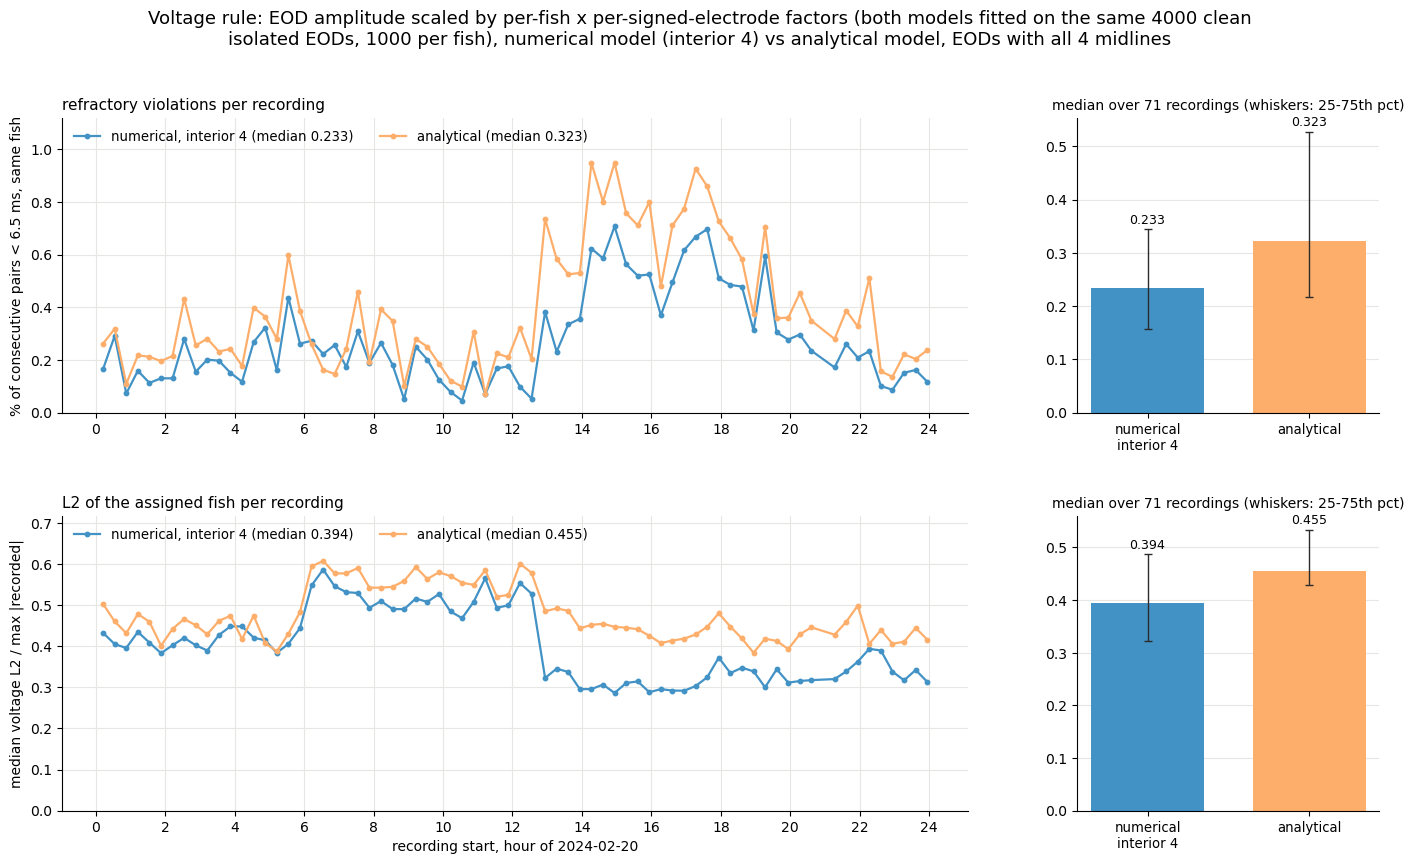

,violations median %,L2 median
model,,
"numerical, interior 4",0.2332,0.3936
"analytical, same factor set",0.3226,0.4546


In [12]:
C3 = ['numerical, interior 4', NEW]          # the analytical model with its factors refitted on the same clean set
V3 = pd.concat([V[(V.set == 'EODs with all 4 midlines') & (V.rule == 'voltage L2') & (V.model == C3[0])], VN])
L3 = pd.concat([L[(L.rule == 'not normalized') & (L.model == C3[0])], LN])
LAB = {'numerical, interior 4': 'numerical, interior 4', NEW: 'analytical'}
SHORT = {'numerical, interior 4': 'numerical\ninterior 4', NEW: 'analytical'}
fig, axs = plt.subplots(2, 2, figsize=(17, 9), gridspec_kw=dict(width_ratios=[3, 1], hspace=0.35, wspace=0.18))
for r_, (D, col, yl) in enumerate([(V3, 'pct', f'% of consecutive pairs < {LIM_MS:g} ms, same fish'),
                                   (L3, 'median', 'median voltage L2 / max |recorded|')]):
    ax = axs[r_, 0]
    for m in C3:
        g = D[D.model == m].sort_values('hour')
        ax.plot(g.hour, g[col], '-o', ms=3.2, lw=1.6, color=COL[m], label=f'{LAB[m]} (median {g[col].median():.3f})')
    ax.set_ylabel(yl); ax.set_ylim(0, D[col].max() * 1.18); ax.set_xticks(range(0, 25, 2)); ax.legend(frameon=False, fontsize=9.5, ncol=2, loc='upper left')
    ax.set_title(('refractory violations' if r_ == 0 else 'L2 of the assigned fish') + ' per recording', loc='left', fontsize=11)
    ax = axs[r_, 1]
    for j, m in enumerate(C3):
        y = D[D.model == m][col].to_numpy(); med = np.median(y); q = np.quantile(y, [0.25, 0.75])
        ax.bar(j, med, 0.7, color=COL[m]); ax.errorbar(j, med, yerr=[[med - q[0]], [q[1] - med]], color='#2b2b2b', capsize=3, lw=1)
        ax.text(j, q[1] * 1.01, f'{med:.3f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(range(len(C3))); ax.set_xticklabels([SHORT[m] for m in C3], fontsize=9.5); ax.grid(axis='x', visible=False)
    ax.set_title('median over 71 recordings (whiskers: 25-75th pct)', fontsize=10)
axs[1, 0].set_xlabel('recording start, hour of 2024-02-20')
fig.suptitle('Voltage rule: EOD amplitude scaled by per-fish x per-signed-electrode factors (both models fitted on the same 4000 clean\n'
             'isolated EODs, 1000 per fish), numerical model (interior 4) vs analytical model, EODs with all 4 midlines', y=1.0, fontsize=13)
fig.savefig(f'{OUT}/analytical_same_factor_set.png', dpi=110, bbox_inches='tight'); plt.show()
S3 = pd.DataFrame({'violations median %': V3.groupby('model').pct.median(), 'L2 median': L3.groupby('model')['median'].median()}).reindex(C3)
S3.to_csv(f'{OUT}/analytical_same_factor_set_summary.csv'); S3.round(4)

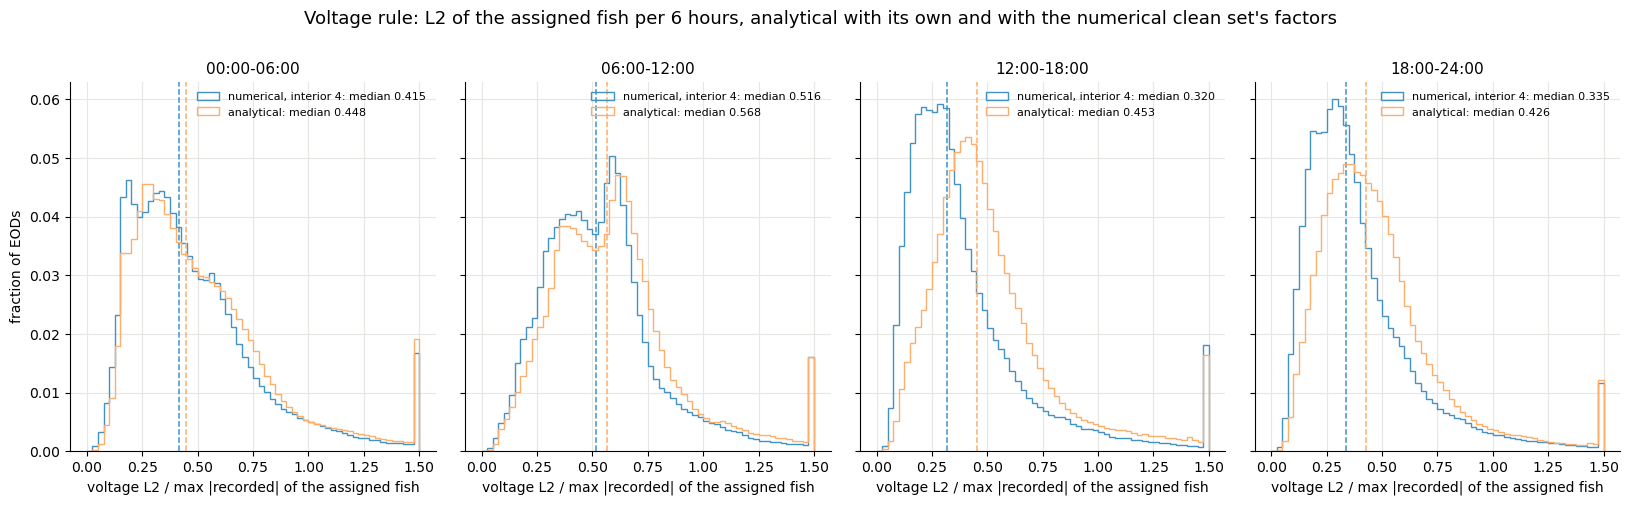

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True, gridspec_kw=dict(wspace=0.08))
for ax, b in zip(axs, BLOCKS):
    for m in C3:
        x = PER[m][b]; w = np.ones(len(x)) / len(x); med = np.median(x)
        ax.hist(np.clip(x, bins[0], bins[-1]), bins=bins, weights=w, histtype='step', lw=1.6, color=COL[m],
                label=f'{LAB[m].splitlines()[0]}: median {med:.3f}')
        ax.axvline(med, color=COL[m], ls='--', lw=1.1)
    ax.set_title(f'{b[0]:02d}:00-{b[1]:02d}:00', fontsize=11); ax.set_xlabel('voltage L2 / max |recorded| of the assigned fish')
    ax.legend(frameon=False, fontsize=8, loc='upper right')
axs[0].set_ylabel('fraction of EODs')
fig.suptitle('Voltage rule: L2 of the assigned fish per 6 hours, analytical with its own and with the numerical clean set\'s factors', y=1.03, fontsize=13)
fig.savefig(f'{OUT}/voltage_l2_distribution_per_6h_same_factor_set.png', dpi=110, bbox_inches='tight'); plt.show()

## Voltage L2 in volts (not divided by the recording's peak)

Same two models and EODs as above (voltage rule, factors fitted on the same 4000 clean EODs, EODs with all 4 midlines), now
||recorded - predicted|| in volts for the assigned fish. **The two recorded quantities differ**: the numerical model is compared with
the main phase (each pair's demeaned trace at the sample of the largest |V|), the analytical model with Denis' signed
peak-to-peak, which is larger. The figure keeps the layout above (refractory violations on top); the table under it gives each model's median max |recorded| for scale.

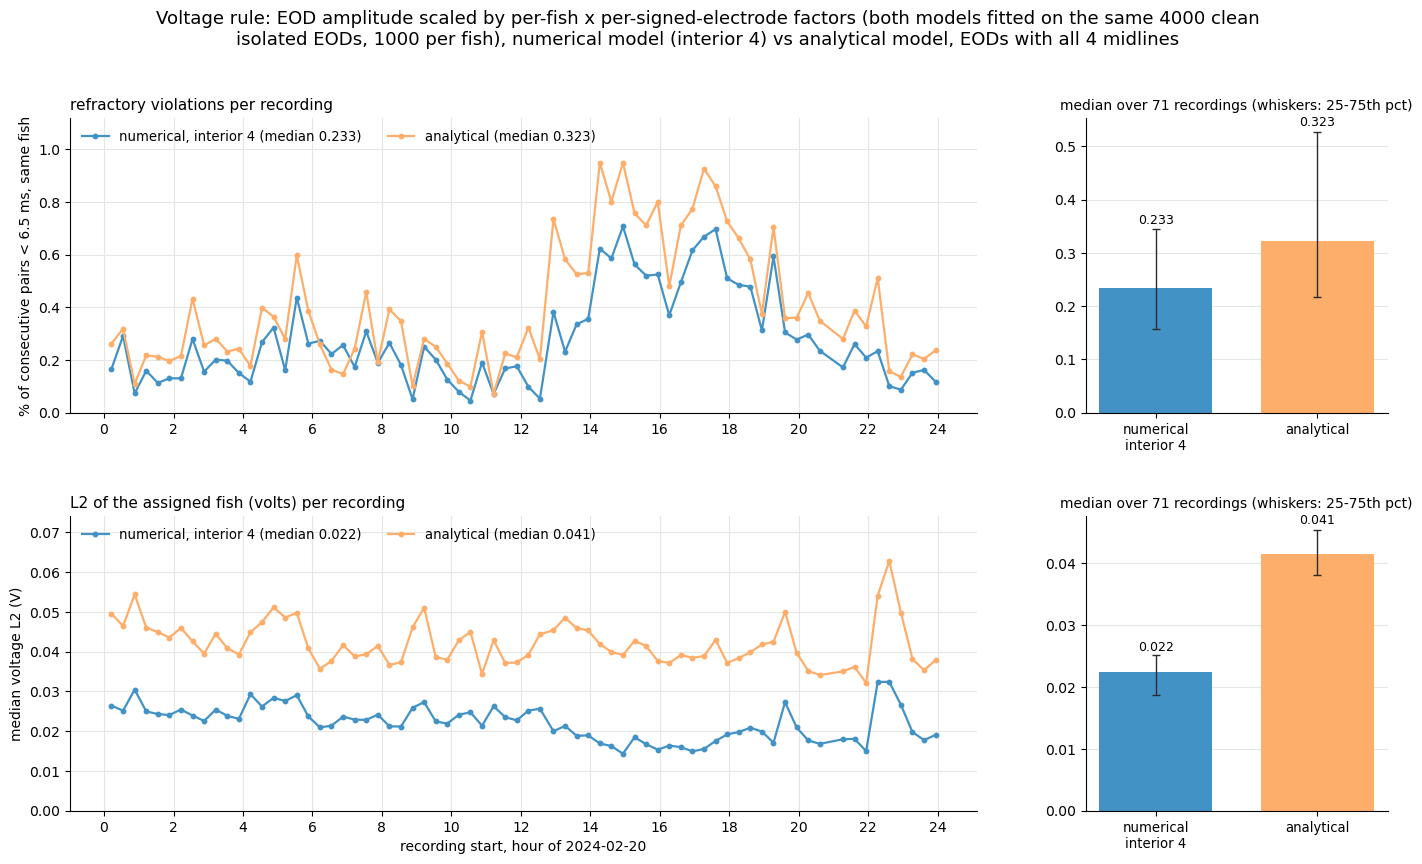

,median_l2_V,median_max_recorded_V
model,,
"numerical, interior 4",0.0224,0.0602
"analytical, same factor set",0.0414,0.0966


In [14]:
rows = []
for t in VIDEOS:
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['all fish have a midline'], keep_default_na=False)
    dset = d['all fish have a midline'].astype(str).str.lower().eq('true').to_numpy()
    z = np.load(f'{BASE}/cluster_assign/mine_N150_tank_barriers_int4/Voltage_prediction_4fish_2024-02-20T{t}.npz')
    num = (pick_l2(z['l2_volt'], labels(z['pick_voltage'])), np.abs(z['recorded']).max(1))
    z = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz', allow_pickle=True); R_, M_, fr = z['recorded_ptp'], z['predicted_ptp'], z['frame']
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}
    pole_f = nearer_pole(mz['mids']); idx = np.array([gi.get(int(k), -1) for k in fr])
    pole = np.where(idx[:, None, None] >= 0, pole_f[np.clip(idx, 0, None)], 0)
    dv = np.linalg.norm(R_[:, None] - A2[None, :, None] * E2[np.arange(10)[None, None, :], pole] * M_, axis=2)
    k = np.where(np.isfinite(dv).any(1), np.nanargmin(np.where(np.isfinite(dv), dv, np.inf), 1), -1)
    ana = (pick_l2(dv, k), np.abs(R_).max(1))
    for m, (x, rmax) in (('numerical, interior 4', num), (NEW, ana)):
        ok = dset & np.isfinite(x)
        rows.append(dict(recording=t, hour=hours(t), model=m, n=int(ok.sum()), median_l2_V=np.median(x[ok]),
                         median_max_recorded_V=np.median(rmax[ok])))
    del mz, pole_f, pole
LV = pd.DataFrame(rows); LV.to_csv(f'{OUT}/voltage_l2_volts_per_recording_same_factor_set.csv', index=False)

fig, axs = plt.subplots(2, 2, figsize=(17, 9), gridspec_kw=dict(width_ratios=[3, 1], hspace=0.35, wspace=0.18))
for r_, (D, col, yl, ttl) in enumerate([(V3, 'pct', f'% of consecutive pairs < {LIM_MS:g} ms, same fish', 'refractory violations'),
                                        (LV, 'median_l2_V', 'median voltage L2 (V)', 'L2 of the assigned fish (volts)')]):
    ax = axs[r_, 0]
    for m in C3:
        g = D[D.model == m].sort_values('hour')
        ax.plot(g.hour, g[col], '-o', ms=3.2, lw=1.6, color=COL[m], label=f'{LAB[m]} (median {g[col].median():.3f})')
    ax.set_ylabel(yl); ax.set_ylim(0, D[col].max() * 1.18); ax.set_xticks(range(0, 25, 2))
    ax.legend(frameon=False, fontsize=9.5, ncol=2, loc='upper left'); ax.set_title(ttl + ' per recording', loc='left', fontsize=11)
    ax = axs[r_, 1]
    for j, m in enumerate(C3):
        y = D[D.model == m][col].to_numpy(); med = np.median(y); q = np.quantile(y, [0.25, 0.75])
        ax.bar(j, med, 0.7, color=COL[m]); ax.errorbar(j, med, yerr=[[med - q[0]], [q[1] - med]], color='#2b2b2b', capsize=3, lw=1)
        ax.text(j, q[1] * 1.01, f'{med:.3f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(range(len(C3))); ax.set_xticklabels([SHORT[m] for m in C3], fontsize=9.5); ax.grid(axis='x', visible=False)
    ax.set_title('median over 71 recordings (whiskers: 25-75th pct)', fontsize=10)
axs[1, 0].set_xlabel('recording start, hour of 2024-02-20')
fig.suptitle('Voltage rule: EOD amplitude scaled by per-fish x per-signed-electrode factors (both models fitted on the same 4000 clean\n'
             'isolated EODs, 1000 per fish), numerical model (interior 4) vs analytical model, EODs with all 4 midlines', y=1.0, fontsize=13)
fig.savefig(f'{OUT}/analytical_same_factor_set_volts.png', dpi=110, bbox_inches='tight'); plt.show()
LV.groupby('model')[['median_l2_V', 'median_max_recorded_V']].median().reindex(C3).round(4)